# Crystalline Sample Phase Retrieval

> Georgios Varnavides | Jan 12 2025  
>
> Sample: thin strontium titanate (STO)  
> Sampling conditions: Nyquist  
> Imaging conditions: 300 kV, 20 mrad; in focus, defocus, and defocus + coma  
> Dose conditions: 1e6 and 1e4 e/A2  

A simulated SrTiO3 unit cell under three sets of aberrations and two doses. We compare the six
deconvolution kernels of `ptycho_direct_01_kernels` across them, upsample a subsampled scan, estimate the defocus from the data,
and compare with iterative ptychography.

In [1]:
# %load_ext autoreload
# %autoreload 2

In [2]:
import quantem as em
import numpy as np

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

The dataset is 6D. Its first two axes step the defocus (`C10` of 0 and 50 A) and the coma (`C21` of
0 and 5000 A), and the scan covers a single unit cell. We use three of the four combinations.

In [3]:
dataset = em.core.io.load("../../data/STO_20mrad_C10_C21_Nyquist.zip")
dataset

Dataset(shape=(2, 2, 32, 32, 192, 192), dtype=float32, name='6d dataset')
  sampling: [5.000000e+01 5.000000e+03 1.221875e-01 1.221875e-01 8.391939e-01
 8.391939e-01]
  units: ['A', 'A', 'A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

In [4]:
energy = 300e3
semiangle_cutoff = 20

aberrations=[
    [
        {"C10":C10,"C21":C21,"phi21":-0.8}
        for C21 in (0,dataset.sampling[1])
    ]
    for C10 in (0,dataset.sampling[0])
]
aberrations_flat = [aberrations[0][0], aberrations[1][0], aberrations[1][1]]
aberrations_flat

[{'C10': 0, 'C21': 0, 'phi21': -0.8},
 {'C10': np.float64(50.0), 'C21': 0, 'phi21': -0.8},
 {'C10': np.float64(50.0), 'C21': np.float64(5000.0), 'phi21': -0.8}]

## Finite dose

Poisson counts at 1e6 and 1e4 electrons per square Angstrom, for each set of aberrations:

In [5]:
def add_poisson_noise(
    dataset,
    electrons_per_area,
):
    if electrons_per_area == np.inf:
        return dataset
    electrons_per_probe = electrons_per_area * dataset.sampling[:2].prod()
    
    dataset_noisy = dataset.copy()
    dataset_noisy.array = np.random.poisson(dataset.array * electrons_per_probe)
    return dataset_noisy

In [6]:
np.random.seed(2025)
noisy_datasets = [
    [
        add_poisson_noise(
            dataset[index],
            dose
        ) for dose in (1e6,1e4)
    ]
    for index in ((0,0),(1,0),(1,1))
]

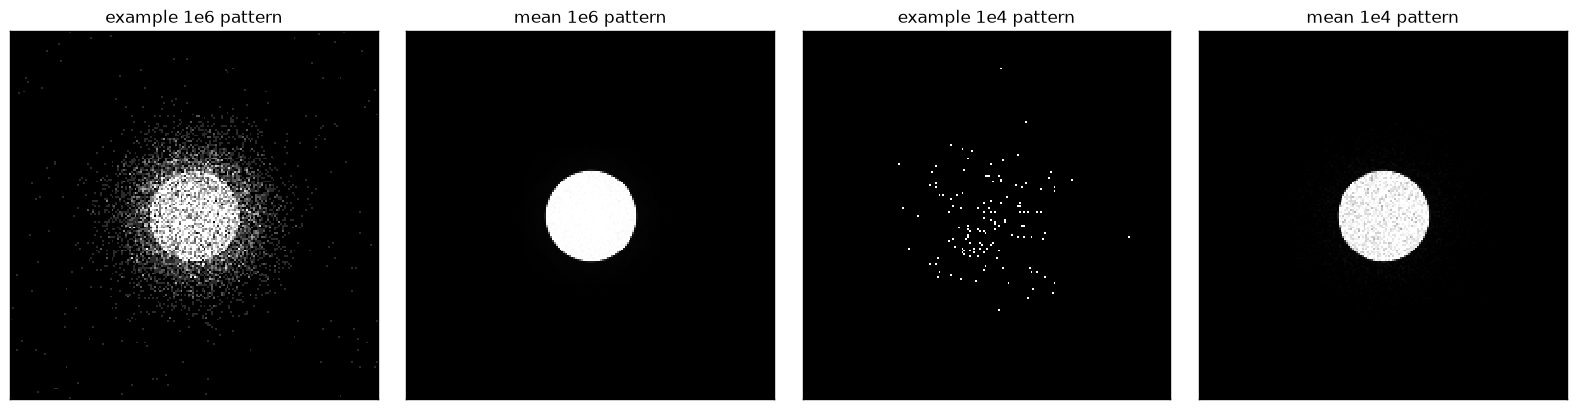

In [7]:
em.visualization.show_2d(
    [
        noisy_datasets[0][0][0,0].array,
        noisy_datasets[0][0].mean((0,1)),
        noisy_datasets[0][1][0,0].array,
        noisy_datasets[0][1].mean((0,1)),
    ],
    title=[
        "example 1e6 pattern","mean 1e6 pattern","example 1e4 pattern","mean 1e4 pattern"
    ]
);

## Direct ptychography

One `DirectPtychography` object per dataset, each given the true aberrations and rotation angle:

In [8]:
direct_ptychography_classes = [
    [
        em.diffractive_imaging.DirectPtychography.from_dataset4d(
            x,
            energy=energy,
            semiangle_cutoff=semiangle_cutoff,
            rotation_angle=0,
            aberration_coefs=aberrations_flat[index],
            verbose=False,
            # device='gpu',
        ) for x in sublist
    ] for index,sublist in enumerate(noisy_datasets)
]

### Deconvolution kernels

`deconvolution_kernel` selects one of the six kernels of `ptycho_direct_01_kernels`. Here they
are on the defocused, high-dose dataset:

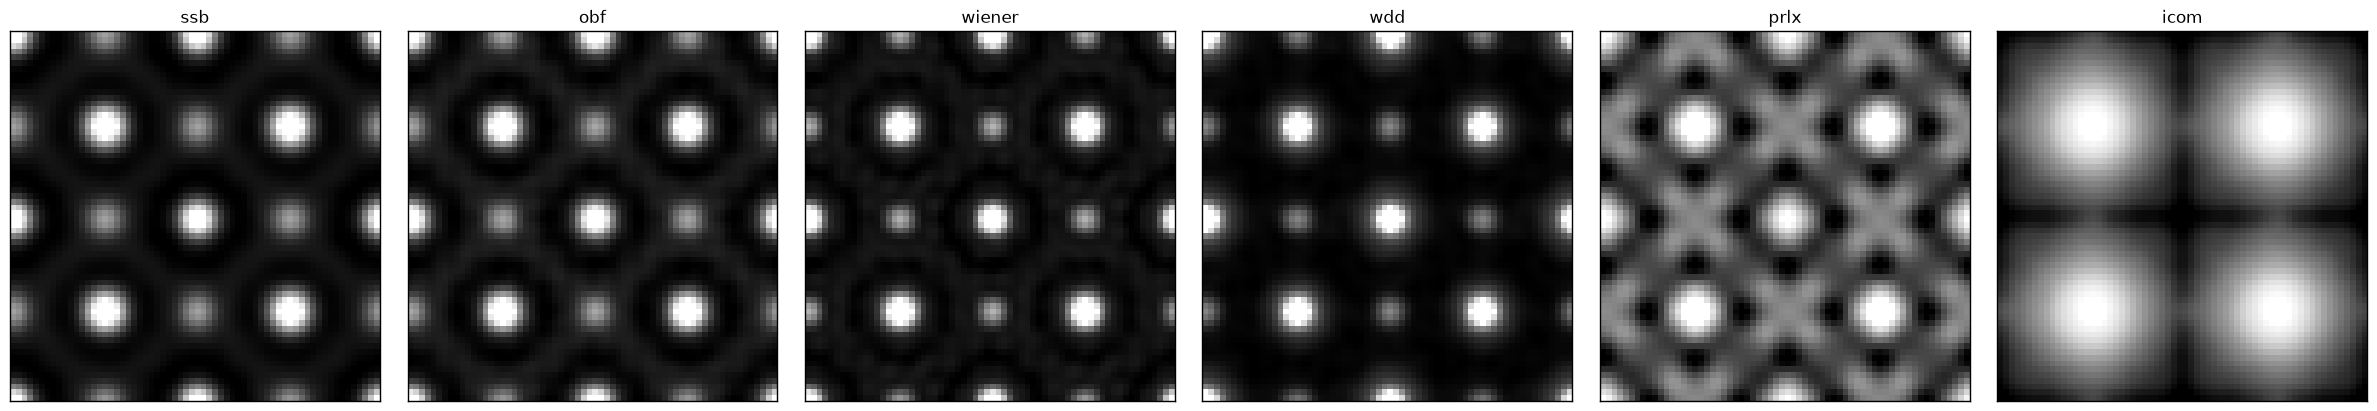

In [9]:
ssb_obj = direct_ptychography_classes[1][0].reconstruct(deconvolution_kernel='ssb').obj
obf_obj = direct_ptychography_classes[1][0].reconstruct(deconvolution_kernel='obf').obj
wiener_obj = direct_ptychography_classes[1][0].reconstruct(deconvolution_kernel='wiener').obj
wdd_obj = direct_ptychography_classes[1][0].reconstruct(deconvolution_kernel='wdd').obj
parallax_obj = direct_ptychography_classes[1][0].reconstruct(deconvolution_kernel='parallax').obj
icom_obj = direct_ptychography_classes[1][0].reconstruct(deconvolution_kernel='icom').obj

em.visualization.show_2d(
    [
        np.tile(ssb_obj,(2,2)),
        np.tile(obf_obj,(2,2)),
        np.tile(wiener_obj,(2,2)),
        np.tile(wdd_obj,(2,2)),
        np.tile(parallax_obj,(2,2)),
        np.tile(icom_obj,(2,2)),
    ],
    title=["ssb","obf","wiener","wdd","prlx","icom"]
);

The images are tiled 2 x 2, since the scan covers one unit cell. The four deconvolution kernels
resolve the atomic columns, parallax shows the lattice with different contrast, and the center of
mass is blurred.

### Effect of aberrations and dose

`_reconstruct_all_permutations` runs all six kernels with the same settings. We run it for each set
of aberrations at both doses:

In [10]:
kwargs = {
    "title":["single-sideband","optimum-bright-field","wiener","wigner-distribution-deconvolution","parallax","center-of-mass"],
    "norm":"minmax",
    "axsize":(3,3),
}

100%|██████████| 6/6 [00:00<00:00,  6.80it/s]


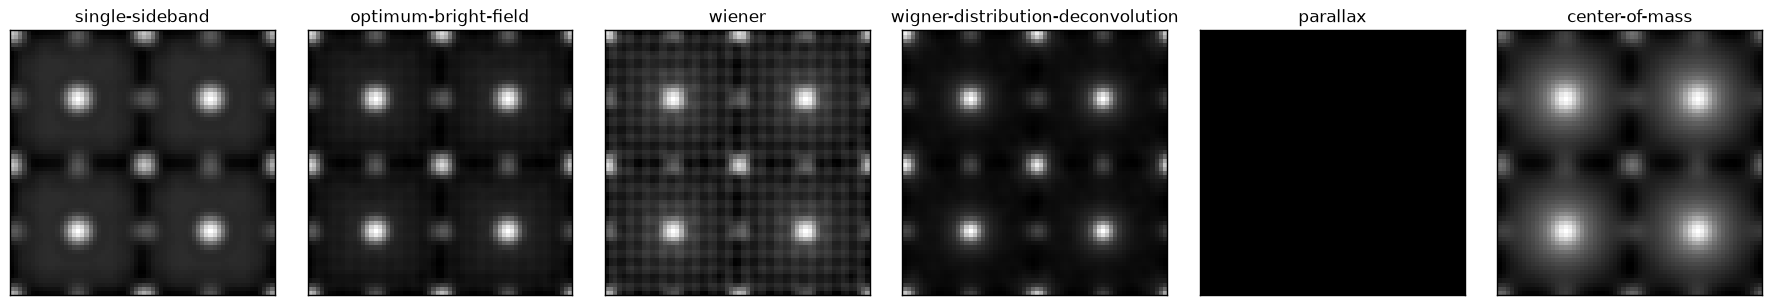

In [11]:
# in-focus, high dose
recons = direct_ptychography_classes[0][0]._reconstruct_all_permutations(verbose=True)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

100%|██████████| 6/6 [00:00<00:00,  6.61it/s]


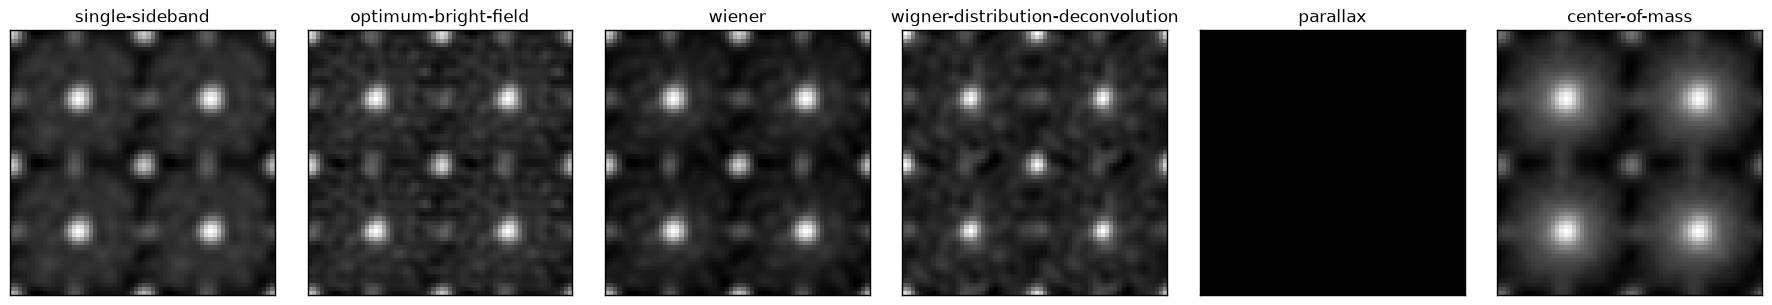

In [12]:
# in-focus, low dose
recons = direct_ptychography_classes[0][1]._reconstruct_all_permutations(verbose=True)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

100%|██████████| 6/6 [00:00<00:00,  6.72it/s]


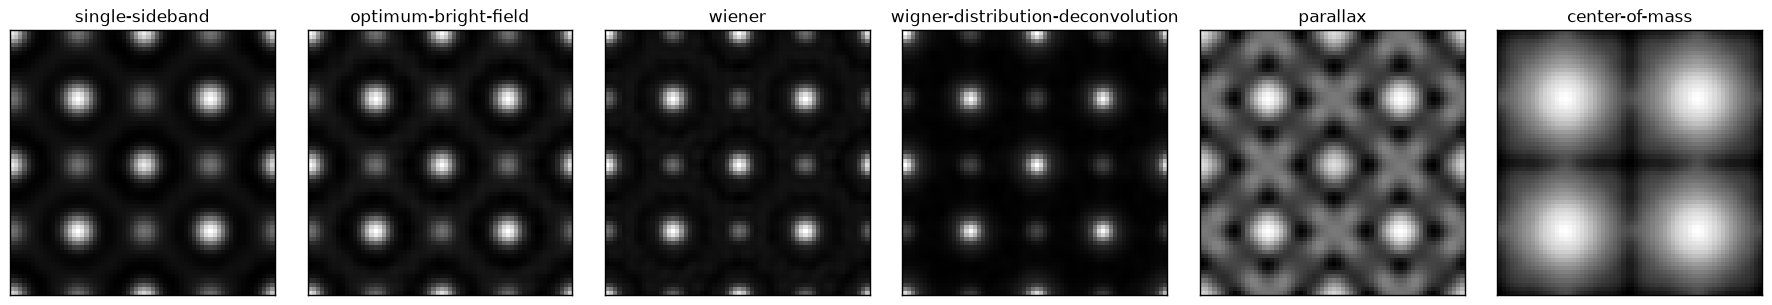

In [13]:
# defocus, high dose
recons = direct_ptychography_classes[1][0]._reconstruct_all_permutations(verbose=True)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

100%|██████████| 6/6 [00:00<00:00,  6.66it/s]


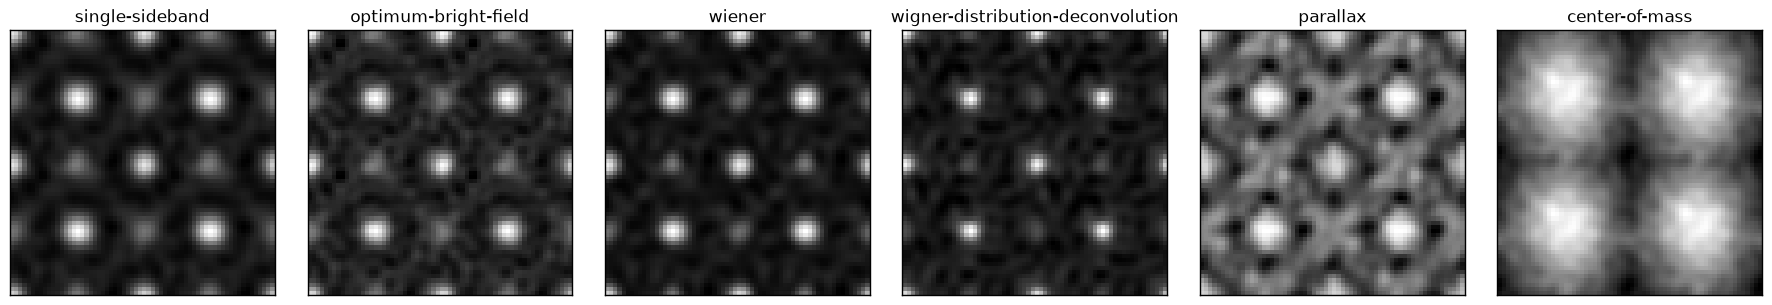

In [14]:
# defocus, low dose
recons = direct_ptychography_classes[1][1]._reconstruct_all_permutations(verbose=True)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

100%|██████████| 6/6 [00:00<00:00,  6.59it/s]


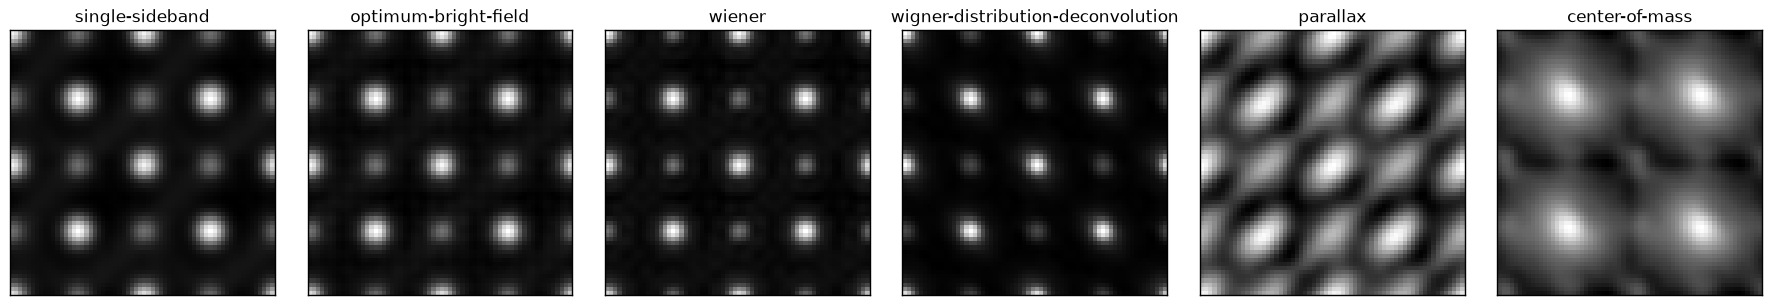

In [15]:
# defocus + coma, high dose
recons = direct_ptychography_classes[2][0]._reconstruct_all_permutations(verbose=True)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

100%|██████████| 6/6 [00:00<00:00,  6.60it/s]


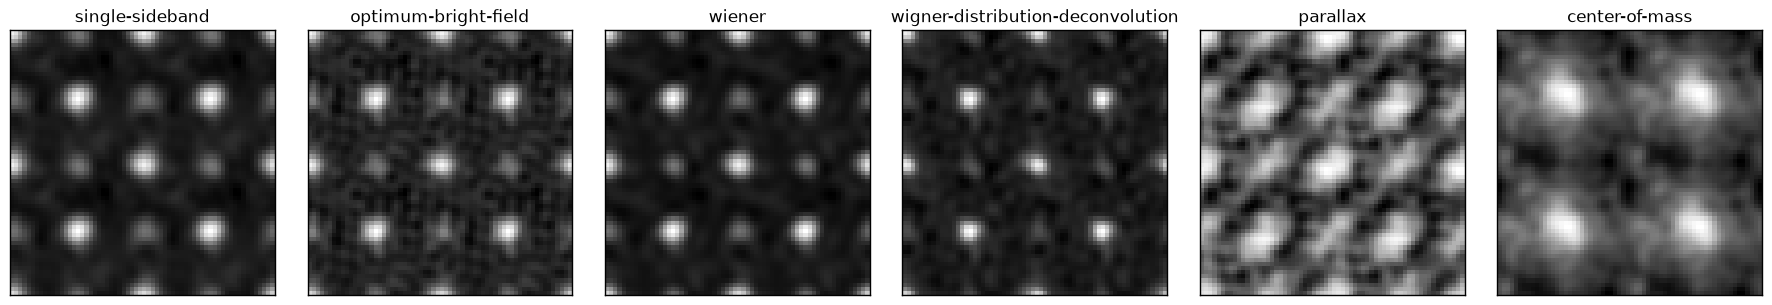

In [16]:
# defocus + coma, low dose
recons = direct_ptychography_classes[2][1]._reconstruct_all_permutations(verbose=True)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

In focus, parallax has no contrast, since nothing shifts the bright-field images relative to one
another, and the center of mass is at its sharpest. The deconvolution kernels handle every set of
aberrations, while coma distorts the parallax image. At 1e4, OBF and WDD are the noisiest kernels,
and SSB and Wiener the cleanest. Wiener also shows a faint grid in focus at the higher dose.

### Upsampling

Keeping every second scan position in each direction undersamples the bright field.
`upsampling_factor=2` recovers the full-resolution reconstruction from it, for every kernel but the
center of mass:

100%|██████████| 6/6 [00:00<00:00,  7.67it/s]


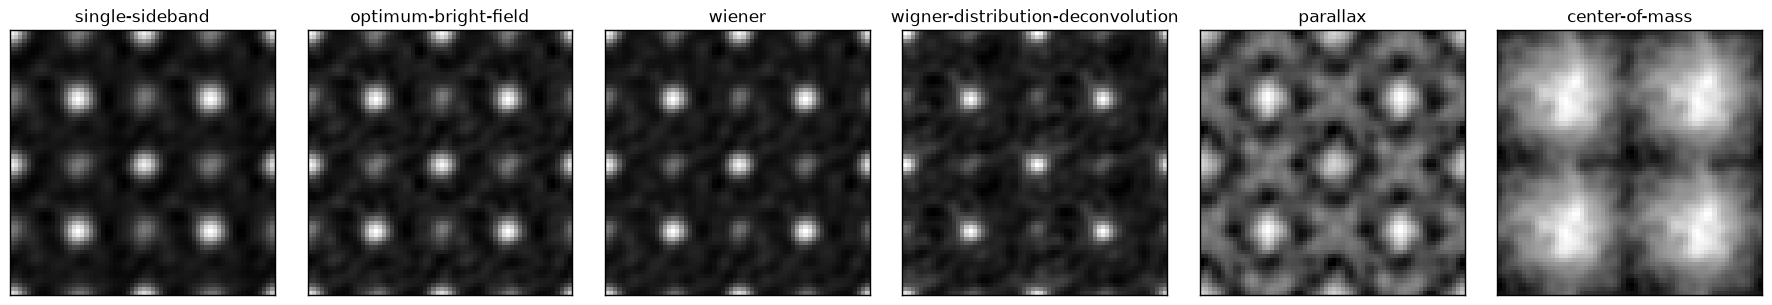

In [17]:
subsampled_noisy_dataset = add_poisson_noise(
    dataset[1,0,::2,::2],
    1e4
)
subsampled_noisy_direct_ptychography_class = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    subsampled_noisy_dataset,
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=0,
    aberration_coefs=aberrations_flat[1],
    verbose=False,
    # device='gpu',
)

recons = subsampled_noisy_direct_ptychography_class._reconstruct_all_permutations(
    upsampling_factor=2,
    verbose=True
)
recons_tiled = [np.tile(recon,(2,2)) for recon in recons]

em.visualization.show_2d(
    recons_tiled,
    **kwargs
);

Apart from the center of mass, these match the full scan at the same dose above.

## Parameter estimation

Above, we used the known aberrations. When they are not known, we can estimate them by minimizing
the residual of the reconstruction's forward model (`residual_loss`), either by Bayesian
optimization or by gradient descent. Here we estimate the defocus of the defocused, high-dose
dataset, whose true value is 50 A. `ptycho_direct_06_hyperparameters` covers these methods in
detail.

### Bayesian optimization

With `optuna`, about 50 trials per parameter:

Best trial: 45. Best value: 0.447861: 100%|██████████| 50/50 [00:06<00:00,  7.24it/s]


Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': 50.0, 'C21': 0.0, 'phi21': -0.8},
  initial_rotation_angle_deg=0,
  optimized_aberrations={'C10': 52.62452925417263, 'C21': 0.0, 'phi21': -0.8},
)


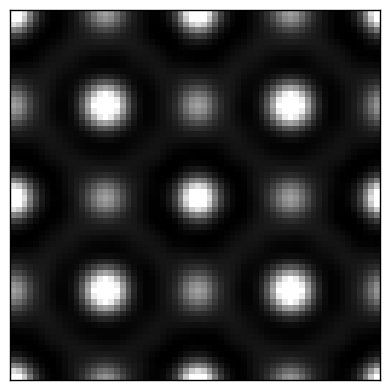

In [18]:
direct_ptychography_classes[1][0].optimize_hyperparameters(
    aberration_coefs={
        "C10":em.diffractive_imaging.OptimizationParameter(
            0,200
        )
    },
    n_trials=50,
    deconvolution_kernel='obf',
    verbose=True,
)

em.visualization.show_2d(
    np.tile(
        direct_ptychography_classes[1][0].reconstruct().obj,
        (2,2)
    )
);

It finds `C10` = 52.6 A, against the true 50 A.

### Gradient fitting

`fit_hyperparameters_gradient` minimizes the residual by automatic differentiation. We start it
from no defocus and a rotation angle 10 degrees off, and fit the defocus, the two-fold astigmatism
and the rotation together:

Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': 50.0, 'C21': 0.0, 'phi21': -0.8},
  initial_rotation_angle_deg=0,
  optimized_aberrations={'C10': 52.34148025512695, 'C21': 0.0, 'phi21': -0.8, 'C12': 0.06748390942811966, 'phi12': -1.0655561709427275e-05},
  optimized_rotation_angle_deg=0.02016448974609375,
)


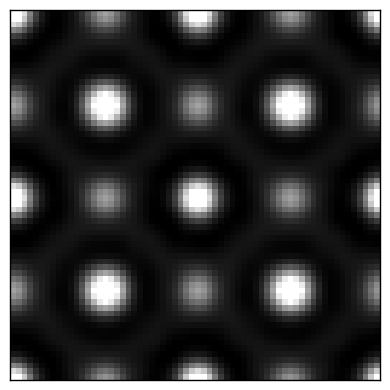

In [19]:
# gradient descent on the residual, from C10 = 0 and a rotation angle 10 degrees off
direct_ptychography_classes[1][0].hyperparameter_state.optimized_aberrations = {"C10": 0.0}
direct_ptychography_classes[1][0].hyperparameter_state.optimized_rotation_angle = 10.0

direct_ptychography_classes[1][0].fit_hyperparameters_gradient(
    ("C10", "C12", "phi12", "rotation_angle"),
    deconvolution_kernel="obf",
    verbose=True,
)

em.visualization.show_2d(
    np.tile(
        direct_ptychography_classes[1][0].reconstruct().obj,
        (2,2)
    )
);

It recovers `C10` = 52.3 A, with 0.07 A of astigmatism and the rotation within 0.02 degrees of the
truth.

## Iterative ptychography comparison

For completeness, a single-slice iterative reconstruction of the subsampled dataset with
`PtychoLite`, given the same aberrations:

In [20]:
pdset = em.diffractive_imaging.PtychographyDatasetRaster.from_dataset4dstem(
    subsampled_noisy_dataset
)

pdset.preprocess(
    force_com_rotation=0,
    force_com_transpose=0,
    plot_com=False,
    probe_energy=300e3,
)

Forcing best fit rotation to 0 degrees.
Forcing transpose of intensities to 0.


Normalizing intensities: 100%|██████████| 256/256 [00:00<00:00, 1297.66probe position/s]


In [21]:
iterative_ptycho = em.diffractive_imaging.PtychoLite.from_dataset(
    dset=pdset,
    num_slices=1,
    num_probes=1,
    energy=300e3,
    polar_parameters= aberrations_flat[1],
    semiangle_cutoff=20,
    obj_padding_px=(0,0),
).reconstruct(
    num_iters=100,
    # device="gpu",
    batch_size=128
)

Iter 100/100, Loss: 7.851e+01: 100%|██████████| 100/100 [00:18<00:00,  5.28it/s]


and the direct reconstruction of the same data, upsampled twice:

In [22]:
direct_ptycho_phase = subsampled_noisy_direct_ptychography_class.reconstruct(
    upsampling_factor=2
).obj

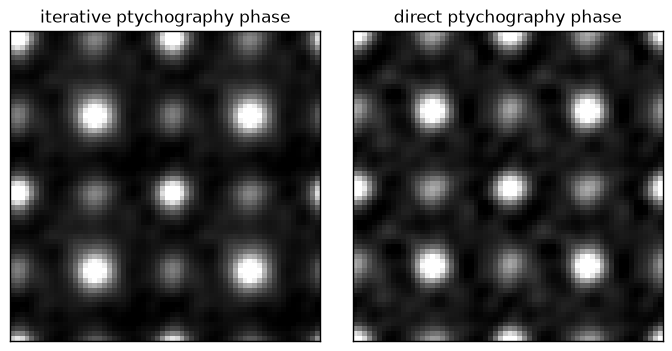

In [23]:
em.visualization.show_2d(
    [
        [
            np.tile(np.angle(iterative_ptycho.obj[0]),(2,2)),
            np.tile(direct_ptycho_phase,(2,2)),
        ],
    ],
    title=[
        ["iterative ptychography phase","direct ptychography phase"],
    ],
    axsize=(3.5,3.5)
);

The two show the same columns, with the direct reconstruction a little sharper and noisier.